In the python document, the classes of linear, batchnorm1d, and tanh. Here we try to build a larger neural network than before and build a sandwich MLP to make sure the code work and to see whether a larger neural network can give a better result (lower loss function). 

Along the way, we also want to see the distribution of data/grad of those parameters of different layers dependent on the presence of Batchnorm1d layers. 

There are four distributions that we want to see
* The data of the outputs of tanh layers (not too concentrated on end)
* The grad of the outputs of tanh layers (not too much death or explosion)
* the grad of the parameters (not too much death or explosion)
* the std of the parameters' changing rate versus the std of their data over time (kept in a list ```update```) (converging slowly)

## Preparation

In [1]:
import torch
import math
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline
from layers_torchified import Linear, Batchnorm1d, Tanh

# read file
words = open('../names.txt', 'r').read().splitlines()
words[:10]

# mapping from letters to numbers and reverse
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i, s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s, i in stoi.items()}
vocab_size = len(itos) # 27

# turning the dataset into the structure of [input] [desired output]
block_size = 3 
X, Y = [], []
for word in words:
    context = [0] * block_size 
    for ch in word + '.':
        ix = stoi[ch]
        X.append(context)
        Y.append(ix)
        context = context[1:] + [ix] 
X = torch.tensor(X) 
Y = torch.tensor(Y) 

# split the dataset (tr/dev/ts) (80/10/10)
def build_dataset(words):
    block_size = 3
    X, Y = [], [] 
    for word in words:
        # print(word)
        context = [0] * block_size 
        for ch in word + '.':
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            # print(''.join(itos[i] for i in context), '------>', itos[ix])
            context = context[1:] + [ix] 
    X = torch.tensor(X) 
    Y = torch.tensor(Y)
    print(X.shape, Y.shape)
    return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8 * len(words))
n2 = int(0.9 * len(words))

Xtr, Ytr = build_dataset(words[:n1]) # 80%
Xdev, Ydev = build_dataset(words[n1: n2]) # 10%
Xts, Yts = build_dataset(words[n2:]) # 10%

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


# After first learning iteration without batchnorm1d

In [ ]:
n_embd = 10 # the dimensionality of character embedding vectors
n_hidden= 100 # the number of neurons in the hidden layer of the MLP
g = torch.Generator().manual_seed(2147483647)

C = torch.randn((vocab_size, n_embd),                   generator=g)
layers = [
    Linear(n_embd * block_size, n_hidden), Tanh(),
    Linear(           n_hidden, n_hidden), Tanh(),
    Linear(           n_hidden, n_hidden), Tanh(),
    Linear(           n_hidden, n_hidden), Tanh(),
    Linear(           n_hidden, n_hidden), Tanh(),
    Linear(           n_hidden, vocab_size),
]

with torch.no_grad():
    # last layer: make less confident (first issue), only upon initialization
    layers[-1].weight *= 0.1
    # all other layers: apply gain
    for layer in layers[:-1]:
        if isinstance(layer, Linear):
            layer.weight *= 5/3

parameters = [C] + [p for layer in layers for p in layer.parameters()]
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
    p.requires_grad = True

46497


In [10]:
# same optimization as last time
max_steps = 200000
batch_size = 32
lossi = []
up = []

for i in range(max_steps):

    # minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (batch_size, ), generator = g)
    Xb, Yb = Xtr[ix], Ytr[ix]

    # forward pass
    emb = C[Xb] # embed the characters into vectors
    x = emb.view(emb.shape[0], -1) # concatenate the vectors
    for layer in layers:
        x = layer(x)
    loss = F.cross_entropy(x, Yb) # loss function

    # backward pass
    for layer in layers:
        layer.out.retain_grad() # AFTER_DEBUG: would take out the retain_graph
    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    lr = 0.1 if i < 100000 else 0.01 # step learning rate decay
    for p in parameters:
        p.data -= lr * p.grad

    # track stats
    if i % 10000 == 0:
        print(f"{i:7d}/{max_steps:7d}: {loss.item():.4f}")
    lossi.append(loss.log10().item())
    with torch.no_grad():
        up.append([(lr*p.grad.std() / p.data.std()).log10().item() for p in parameters])

    break

      0/ 200000: 3.2838


Layer  2 (Tanh) | mean +0.02 | std 0.74 | saturated: 18.84%
Layer  4 (Tanh) | mean -0.00 | std 0.68 | saturated: 9.50%
Layer  6 (Tanh) | mean -0.01 | std 0.66 | saturated: 6.50%
Layer  8 (Tanh) | mean -0.04 | std 0.66 | saturated: 6.09%
Layer 10 (Tanh) | mean +0.00 | std 0.67 | saturated: 7.16%


Text(0.5, 1.0, 'activation distribution')

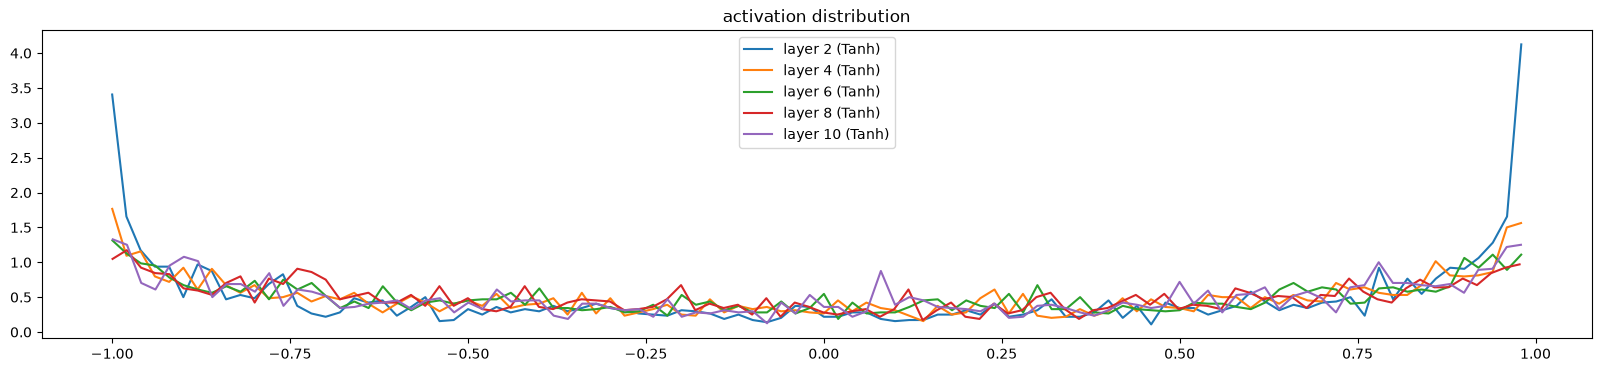

In [21]:
# data of output of tanh layer
plt.figure(figsize=(20,4))
legends = []
for i,layer in enumerate(layers):
    if isinstance(layer, Tanh): 
        t = layer.out
        print('Layer %2s (%4s) | mean %+.2f | std %.2f | saturated: %.2f%%' % (i+1, layer.__class__.__name__, t.mean(), t.std(), (t.abs() > 0.97).float().mean() * 100))
        # saturated measure the percentage of output with abs value greater than 0.97
        # obviously we do not want the percentage to be too high
        hy, hx = torch.histogram(t, density=True)
        plt.plot(hx[:-1].detach(), hy.detach())
        legends.append(f"layer {i+1} ({layer.__class__.__name__})")
plt.legend(legends)
plt.title('activation distribution')

Layer  2 (Tanh) | mean +0.00 | std 0.00
Layer  4 (Tanh) | mean -0.00 | std 0.00
Layer  6 (Tanh) | mean -0.00 | std 0.00
Layer  8 (Tanh) | mean +0.00 | std 0.00
Layer 10 (Tanh) | mean +0.00 | std 0.00


Text(0.5, 1.0, 'gradient distribution')

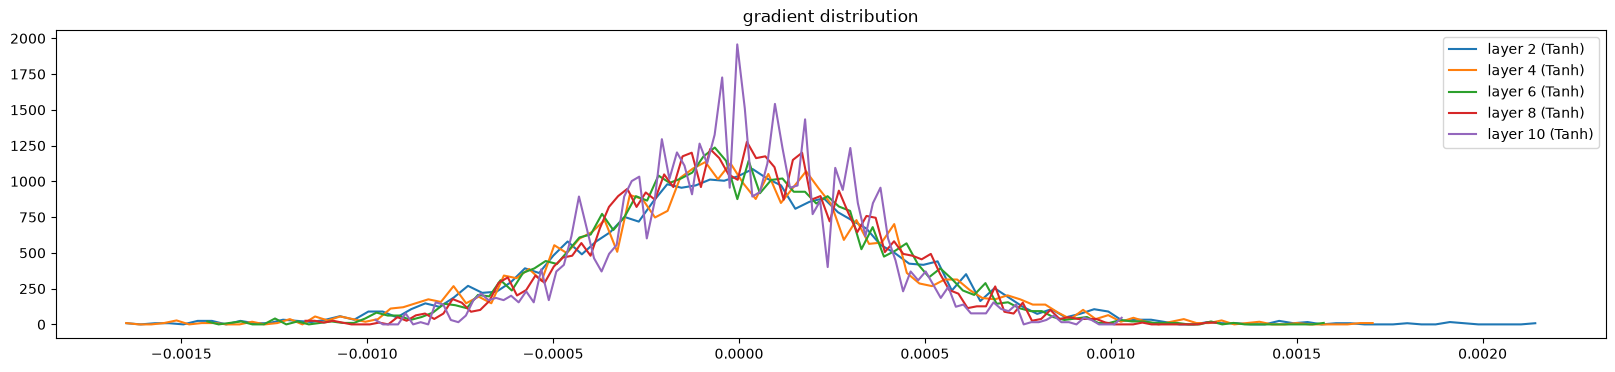

In [22]:
# gradient of the output of tanh layers
plt.figure(figsize=(20,4))
legends = []
for i,layer in enumerate(layers):
    if isinstance(layer, Tanh): 
        t = layer.out.grad
        print('Layer %2s (%4s) | mean %+.2f | std %.2f' % (i+1, layer.__class__.__name__, t.mean(), t.std()))
        # saturated measure the percentage of output with abs value greater than 0.97
        # obviously we do not want the percentage to be too high
        hy, hx = torch.histogram(t, density=True)
        plt.plot(hx[:-1].detach(), hy.detach())
        legends.append(f"layer {i+1} ({layer.__class__.__name__})")
plt.legend(legends)
plt.title('gradient distribution')

Layer   (27, 10) | mean -0.000127 | std 1.486377e-03 | grad:data ratio 1.485300e-03
Layer  (30, 100) | mean +0.000011 | std 1.423018e-03 | grad:data ratio 4.624970e-03
Layer (100, 100) | mean -0.000004 | std 1.135219e-03 | grad:data ratio 6.787700e-03
Layer (100, 100) | mean +0.000004 | std 9.873424e-04 | grad:data ratio 5.922423e-03
Layer (100, 100) | mean -0.000004 | std 8.849816e-04 | grad:data ratio 5.299003e-03
Layer (100, 100) | mean -0.000008 | std 7.443630e-04 | grad:data ratio 4.425939e-03
Layer  (100, 27) | mean +0.000000 | std 2.229021e-02 | grad:data ratio 2.191258e+00


Text(0.5, 1.0, 'gradient distribution')

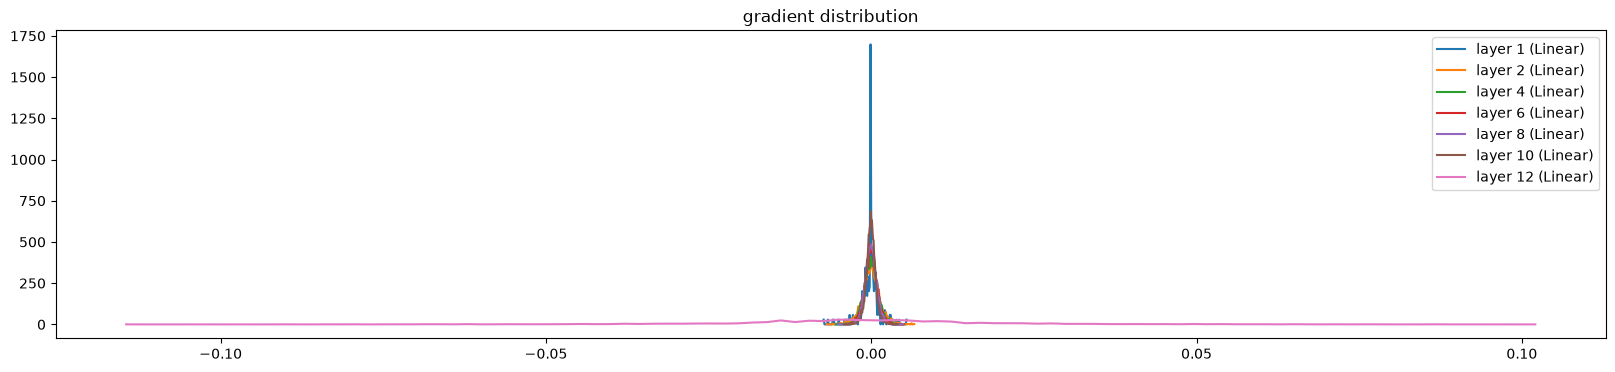

In [25]:
# the gradient of parameters 
plt.figure(figsize=(20,4))
legends = []
for i,p in enumerate(parameters):
    if p.ndim == 2:
        t = p.grad
        print('Layer %10s | mean %+f | std %e | grad:data ratio %e'
              % (tuple(p.shape), t.mean(), t.std(), t.std() / p.std())
              )
        # saturated measure the percentage of output with abs value greater than 0.97
        # obviously we do not want the percentage to be too high
        hy, hx = torch.histogram(t, density=True)
        plt.plot(hx[:-1].detach(), hy.detach())
        legends.append(f"layer {i+1} ({layer.__class__.__name__})")
plt.legend(legends)
plt.title('gradient distribution')

Obviously there is something going on with the last layer (100, 27) since its grad:data ratio is too high compared to other layers, and its graph is too flat as well, which means that its gradients of parameters are too spread out, signaling dramatic update if the iteration of training is to continue. 

This is due to the low confidence (first issue) set during the initialization, which is most clear after the first iteration. 

Also, here we do not include the grad:data ratio over time since we are only iterating 1 times. 

# After 1000 iteration without batchnorm1d

In [33]:
n_embd = 10 # the dimensionality of character embedding vectors
n_hidden= 100 # the number of neurons in the hidden layer of the MLP
g = torch.Generator().manual_seed(2147483647)

C = torch.randn((vocab_size, n_embd),                   generator=g)
layers = [
    Linear(n_embd * block_size, n_hidden), Tanh(),
    Linear(           n_hidden, n_hidden), Tanh(),
    Linear(           n_hidden, n_hidden), Tanh(),
    Linear(           n_hidden, n_hidden), Tanh(),
    Linear(           n_hidden, n_hidden), Tanh(),
    Linear(           n_hidden, vocab_size),
]

with torch.no_grad():
    # last layer: make less confident (first issue), only upon initialization
    layers[-1].weight *= 0.1
    # all other layers: apply gain
    for layer in layers[:-1]:
        if isinstance(layer, Linear):
            layer.weight *= 5/3

parameters = [C] + [p for layer in layers for p in layer.parameters()]
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
    p.requires_grad = True

46497


In [ ]:
# same optimization as last time
max_steps = 200000
batch_size = 32
lossi = []
up = [] # 2d array of grad:data for each parameter over time

for i in range(max_steps):

    # minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (batch_size, ), generator = g)
    Xb, Yb = Xtr[ix], Ytr[ix]

    # forward pass
    emb = C[Xb] # embed the characters into vectors
    x = emb.view(emb.shape[0], -1) # concatenate the vectors
    for layer in layers:
        x = layer(x)
    loss = F.cross_entropy(x, Yb) # loss function

    # backward pass
    for layer in layers:
        layer.out.retain_grad() # AFTER_DEBUG: would take out the retain_graph
    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    lr = 0.1 if i < 100000 else 0.01 # step learning rate decay
    for p in parameters:
        p.data -= lr * p.grad

    # track stats
    if i % 10000 == 0:
        print(f"{i:7d}/{max_steps:7d}: {loss.item():.4f}")
    lossi.append(loss.log10().item())
    with torch.no_grad():
        up.append([(lr*p.grad.std() / p.data.std()).log10().item() for p in parameters])

    if i == 1000:
        break

      0/ 200000: 3.3189


Layer  2 (Tanh) | mean -0.05 | std 0.78 | saturated: 24.66%
Layer  4 (Tanh) | mean +0.00 | std 0.78 | saturated: 23.91%
Layer  6 (Tanh) | mean -0.02 | std 0.80 | saturated: 26.69%
Layer  8 (Tanh) | mean -0.03 | std 0.80 | saturated: 27.19%
Layer 10 (Tanh) | mean +0.02 | std 0.75 | saturated: 17.94%


Text(0.5, 1.0, 'activation distribution')

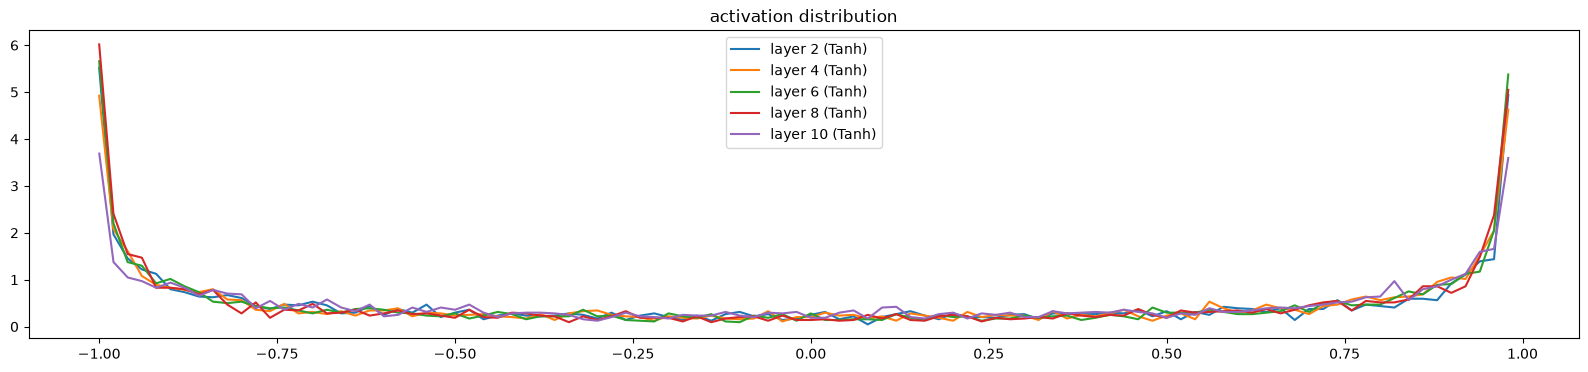

In [32]:
# data of output of tanh layer
plt.figure(figsize=(20,4))
legends = []
for i,layer in enumerate(layers):
    if isinstance(layer, Tanh): 
        t = layer.out
        print('Layer %2s (%4s) | mean %+.2f | std %.2f | saturated: %.2f%%' % (i+1, layer.__class__.__name__, t.mean(), t.std(), (t.abs() > 0.97).float().mean() * 100))
        # saturated measure the percentage of output with abs value greater than 0.97
        # obviously we do not want the percentage to be too high
        hy, hx = torch.histogram(t, density=True)
        plt.plot(hx[:-1].detach(), hy.detach())
        legends.append(f"layer {i+1} ({layer.__class__.__name__})")
plt.legend(legends)
plt.title('activation distribution')

As seen, compared the graph with only one iteration, the saturation rate from the second layer increases, which signals the stabilization of these parameters. If one tries for higher number of iteration, the saturation is going to increase further. 

Layer  2 (Tanh) | mean +0.00 | std 0.00
Layer  4 (Tanh) | mean +0.00 | std 0.00
Layer  6 (Tanh) | mean -0.00 | std 0.00
Layer  8 (Tanh) | mean -0.00 | std 0.00
Layer 10 (Tanh) | mean -0.00 | std 0.00


Text(0.5, 1.0, 'gradient distribution')

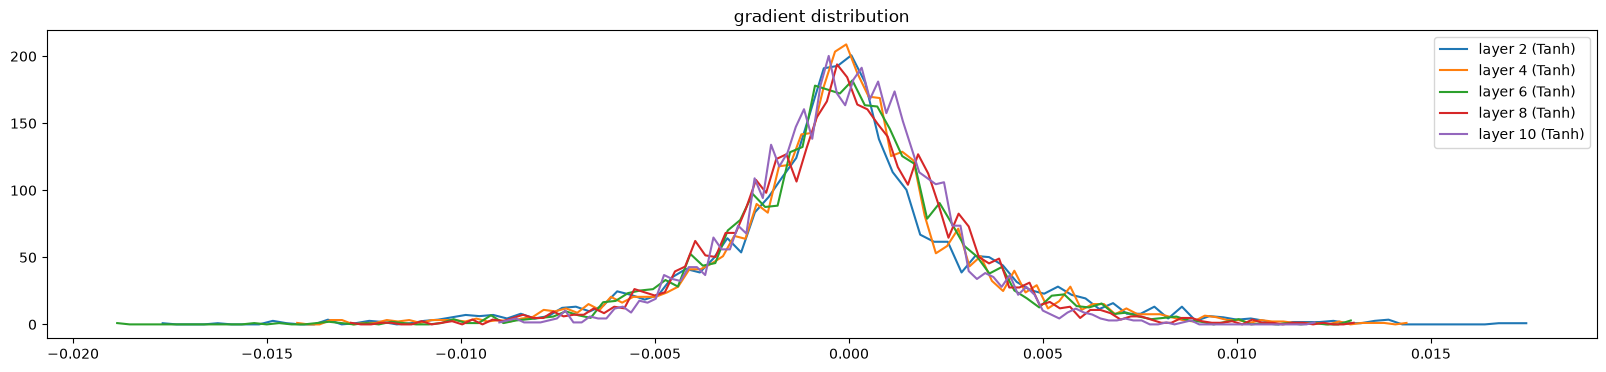

In [36]:
# gradient of the output of tanh layers
plt.figure(figsize=(20,4))
legends = []
for i,layer in enumerate(layers):
    if isinstance(layer, Tanh): 
        t = layer.out.grad
        print('Layer %2s (%4s) | mean %+.2f | std %.2f' % (i+1, layer.__class__.__name__, t.mean(), t.std()))
        # saturated measure the percentage of output with abs value greater than 0.97
        # obviously we do not want the percentage to be too high
        hy, hx = torch.histogram(t, density=True)
        plt.plot(hx[:-1].detach(), hy.detach())
        legends.append(f"layer {i+1} ({layer.__class__.__name__})")
plt.legend(legends)
plt.title('gradient distribution')

Layer   (27, 10) | mean +0.001899 | std 1.349864e-02 | grad:data ratio 1.349210e-02
Layer  (30, 100) | mean +0.000029 | std 1.035566e-02 | grad:data ratio 3.384608e-02
Layer (100, 100) | mean +0.000028 | std 8.265636e-03 | grad:data ratio 4.892880e-02
Layer (100, 100) | mean +0.000005 | std 6.957116e-03 | grad:data ratio 4.089407e-02
Layer (100, 100) | mean +0.000004 | std 6.150592e-03 | grad:data ratio 3.665338e-02
Layer (100, 100) | mean +0.000008 | std 4.974563e-03 | grad:data ratio 2.971172e-02
Layer  (100, 27) | mean -0.000000 | std 2.103009e-02 | grad:data ratio 3.029225e-01


Text(0.5, 1.0, 'gradient distribution')

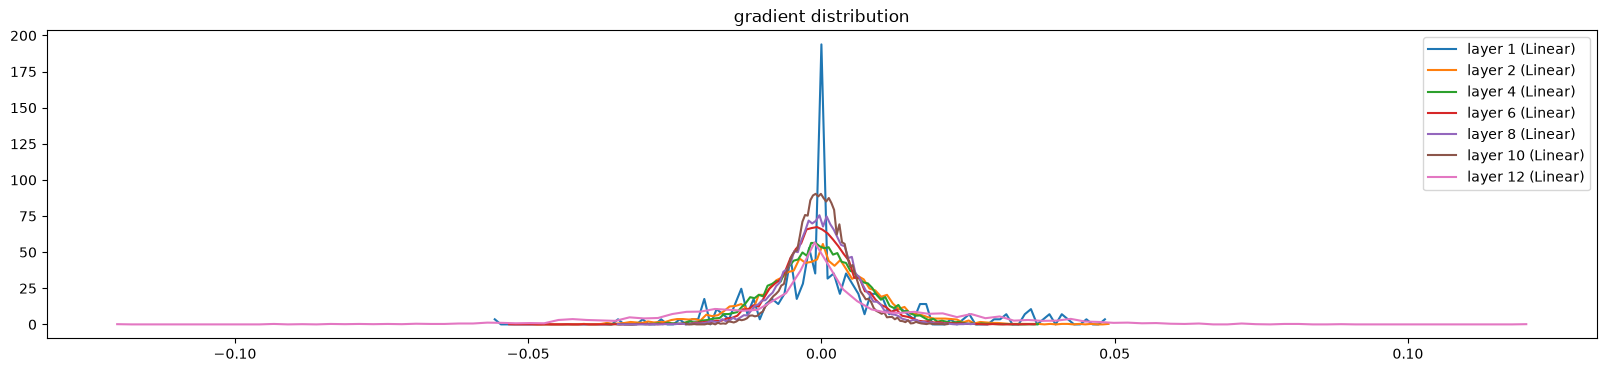

In [37]:
# the gradient of parameters 
plt.figure(figsize=(20,4))
legends = []
for i,p in enumerate(parameters):
    if p.ndim == 2:
        t = p.grad
        print('Layer %10s | mean %+f | std %e | grad:data ratio %e'
              % (tuple(p.shape), t.mean(), t.std(), t.std() / p.std())
              )
        # saturated measure the percentage of output with abs value greater than 0.97
        # obviously we do not want the percentage to be too high
        hy, hx = torch.histogram(t, density=True)
        plt.plot(hx[:-1].detach(), hy.detach())
        legends.append(f"layer {i+1} ({layer.__class__.__name__})")
plt.legend(legends)
plt.title('gradient distribution')

As seen, the distribution of the gradient of the last linear layer is not that flat anymore. 

And although the graph looks dramatically different from the second graph, their spread are actually similar if the dilation of x_axis is taken into account.

Text(0.5, 1.0, 'grad:data ratio over time')

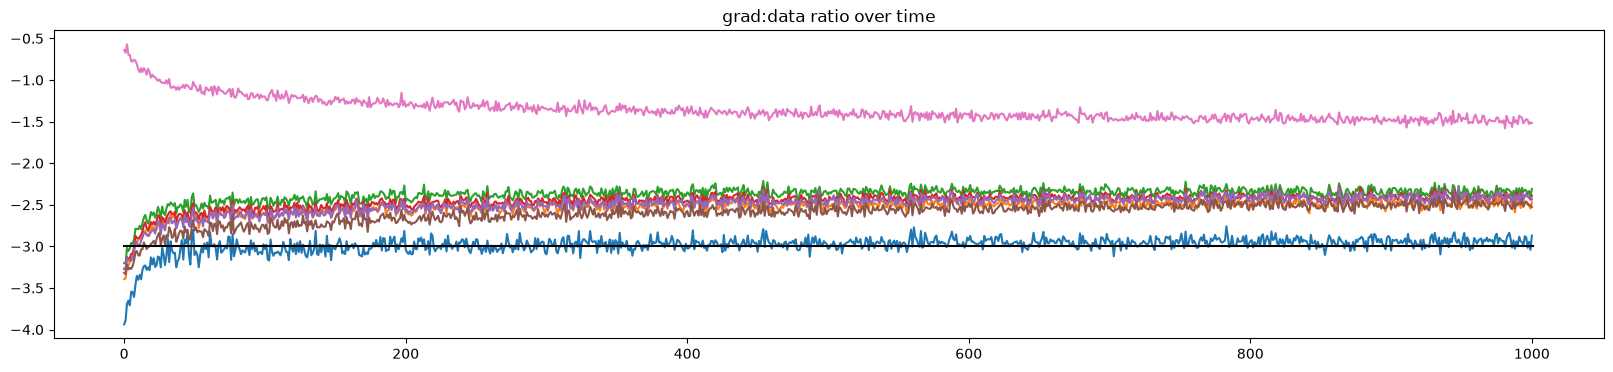

In [40]:
plt.figure(figsize = (20, 4))
legends = []
for i, p in enumerate(parameters):
    if p.ndim == 2:
        plt.plot([up[j][i] for j in range(len(up))])
        legends.append('param %d' % i)
plt.plot([0, len(up)], [-3, -3], 'k') # horizontal line indicating a good ratio
plt.title('grad:data ratio over time')

As seen, the grad:data ratio is converging for all the layers, the high initialization start of the last layer is also due to the low confidence setting of the last layer. 

# After 1000 iteration wit Batchnorm1d

In [21]:
n_embd = 10 # the dimensionality of character embedding vectors
n_hidden= 100 # the number of neurons in the hidden layer of the MLP
g = torch.Generator().manual_seed(2147483647)

C = torch.randn((vocab_size, n_embd),                   generator=g)
layers = [
    Linear(n_embd * block_size, n_hidden, bias = False), Batchnorm1d(n_hidden), Tanh(),
    Linear(           n_hidden, n_hidden, bias = False), Batchnorm1d(n_hidden), Tanh(),
    Linear(           n_hidden, n_hidden, bias = False), Batchnorm1d(n_hidden), Tanh(),
    Linear(           n_hidden, n_hidden, bias = False), Batchnorm1d(n_hidden), Tanh(),
    Linear(           n_hidden, n_hidden, bias = False), Batchnorm1d(n_hidden), Tanh(),
    Linear(           n_hidden, vocab_size, bias = False), Batchnorm1d(vocab_size), # yeah, batchnorm everywhere
]

with torch.no_grad():
    # last layer: make less confident (first issue), only upon initialization
    layers[-1].gamma *= 0.1
    # all other layers: apply gain
    for layer in layers[:-2]:
        if isinstance(layer, Linear):
            layer.weight *= 5/3

parameters = [C] + [p for layer in layers for p in layer.parameters()]
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
    p.requires_grad = True

47024


In [22]:
# same optimization as last time
max_steps = 200000
batch_size = 32
lossi = []
up = [] # 2d array of grad:data for each parameter over time

for i in range(max_steps):

    # minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (batch_size, ), generator = g)
    Xb, Yb = Xtr[ix], Ytr[ix]

    # forward pass
    emb = C[Xb] # embed the characters into vectors
    x = emb.view(emb.shape[0], -1) # concatenate the vectors
    for layer in layers:
        x = layer(x)
    loss = F.cross_entropy(x, Yb) # loss function

    # backward pass
    for layer in layers:
        layer.out.retain_grad() # AFTER_DEBUG: would take out the retain_graph
    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    lr = 0.1 if i < 100000 else 0.01 # step learning rate decay
    for p in parameters:
        p.data -= lr * p.grad

    # track stats
    if i % 10000 == 0:
        print(f"{i:7d}/{max_steps:7d}: {loss.item():.4f}")
    lossi.append(loss.log10().item())
    with torch.no_grad():
        up.append([(lr*p.grad.std() / p.data.std()).log10().item() for p in parameters])

    if i == 1000:
        break

      0/ 200000: 3.2637


Layer  3 (Tanh) | mean -0.00 | std 0.63 | saturated: 3.44%
Layer  6 (Tanh) | mean +0.00 | std 0.64 | saturated: 2.62%
Layer  9 (Tanh) | mean +0.01 | std 0.65 | saturated: 2.59%
Layer 12 (Tanh) | mean +0.00 | std 0.64 | saturated: 2.62%
Layer 15 (Tanh) | mean +0.00 | std 0.65 | saturated: 2.31%


Text(0.5, 1.0, 'activation distribution')

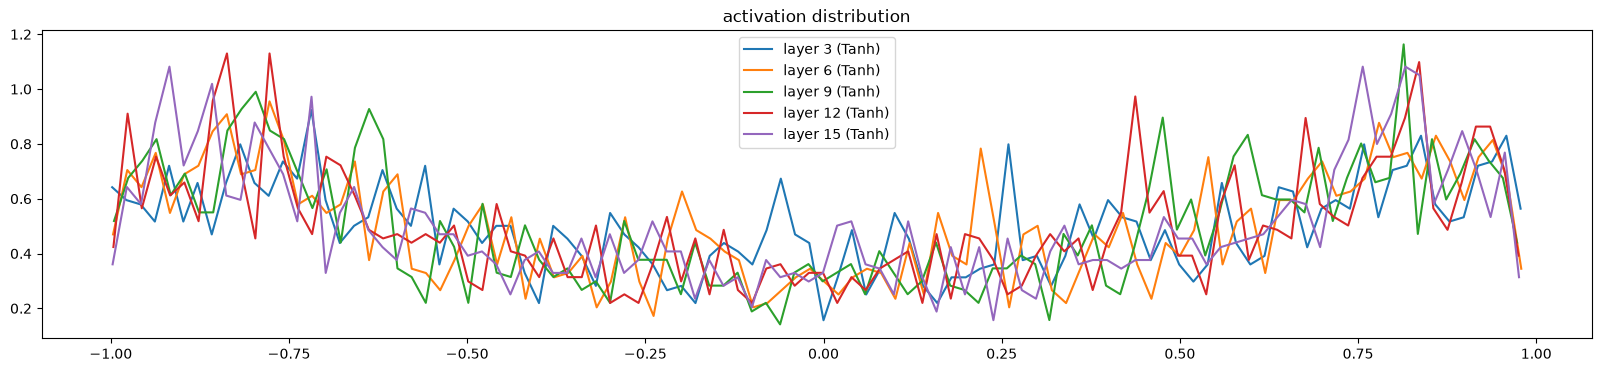

In [23]:
# data of output of tanh layer
plt.figure(figsize=(20,4))
legends = []
for i,layer in enumerate(layers):
    if isinstance(layer, Tanh): 
        t = layer.out
        print('Layer %2s (%4s) | mean %+.2f | std %.2f | saturated: %.2f%%' % (i+1, layer.__class__.__name__, t.mean(), t.std(), (t.abs() > 0.97).float().mean() * 100))
        # saturated measure the percentage of output with abs value greater than 0.97
        # obviously we do not want the percentage to be too high
        hy, hx = torch.histogram(t, density=True)
        plt.plot(hx[:-1].detach(), hy.detach())
        legends.append(f"layer {i+1} ({layer.__class__.__name__})")
plt.legend(legends)
plt.title('activation distribution')

As seen, the distribution of the activation around the end are signifcantly less than before

Layer  3 (Tanh) | mean +0.00 | std 0.00
Layer  6 (Tanh) | mean +0.00 | std 0.00
Layer  9 (Tanh) | mean -0.00 | std 0.00
Layer 12 (Tanh) | mean +0.00 | std 0.00
Layer 15 (Tanh) | mean -0.00 | std 0.00


Text(0.5, 1.0, 'gradient distribution')

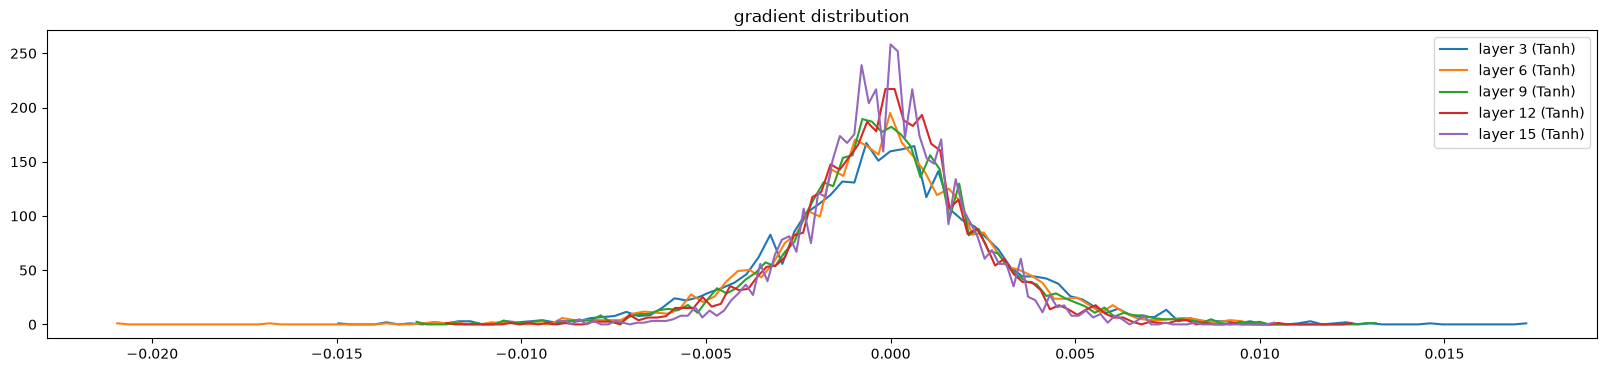

In [24]:
# gradient of the output of tanh layers
plt.figure(figsize=(20,4))
legends = []
for i,layer in enumerate(layers):
    if isinstance(layer, Tanh): 
        t = layer.out.grad
        print('Layer %2s (%4s) | mean %+.2f | std %.2f' % (i+1, layer.__class__.__name__, t.mean(), t.std()))
        # saturated measure the percentage of output with abs value greater than 0.97
        # obviously we do not want the percentage to be too high
        hy, hx = torch.histogram(t, density=True)
        plt.plot(hx[:-1].detach(), hy.detach())
        legends.append(f"layer {i+1} ({layer.__class__.__name__})")
plt.legend(legends)
plt.title('gradient distribution')

Layer   (27, 10) | mean +0.000000 | std 1.029245e-02 | grad:data ratio 1.028156e-02
Layer  (30, 100) | mean +0.000002 | std 7.296819e-03 | grad:data ratio 2.409313e-02
Layer (100, 100) | mean +0.000146 | std 5.845828e-03 | grad:data ratio 3.489403e-02
Layer (100, 100) | mean -0.000050 | std 5.683336e-03 | grad:data ratio 3.423543e-02
Layer (100, 100) | mean +0.000021 | std 4.832285e-03 | grad:data ratio 2.913597e-02
Layer (100, 100) | mean -0.000082 | std 3.895637e-03 | grad:data ratio 2.324906e-02
Layer  (100, 27) | mean -0.000004 | std 1.090213e-02 | grad:data ratio 1.034265e-01


Text(0.5, 1.0, 'gradient distribution')

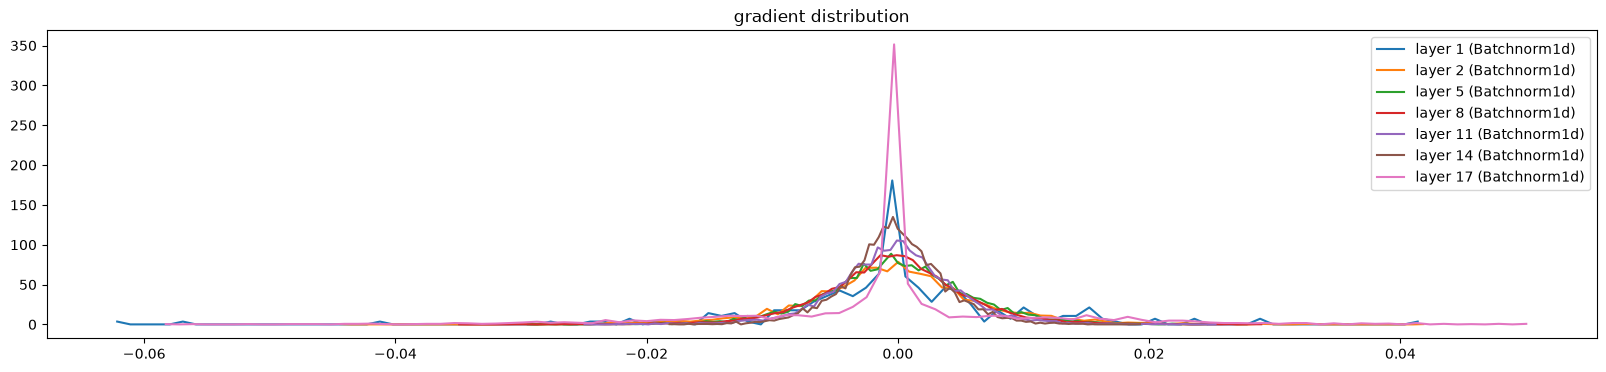

In [25]:
# the gradient of parameters 
plt.figure(figsize=(20,4))
legends = []
for i,p in enumerate(parameters):
    if p.ndim == 2:
        t = p.grad
        print('Layer %10s | mean %+f | std %e | grad:data ratio %e'
              % (tuple(p.shape), t.mean(), t.std(), t.std() / p.std())
              )
        # saturated measure the percentage of output with abs value greater than 0.97
        # obviously we do not want the percentage to be too high
        hy, hx = torch.histogram(t, density=True)
        plt.plot(hx[:-1].detach(), hy.detach())
        legends.append(f"layer {i+1} ({layer.__class__.__name__})")
plt.legend(legends)
plt.title('gradient distribution')

Text(0.5, 1.0, 'grad:data ratio over time')

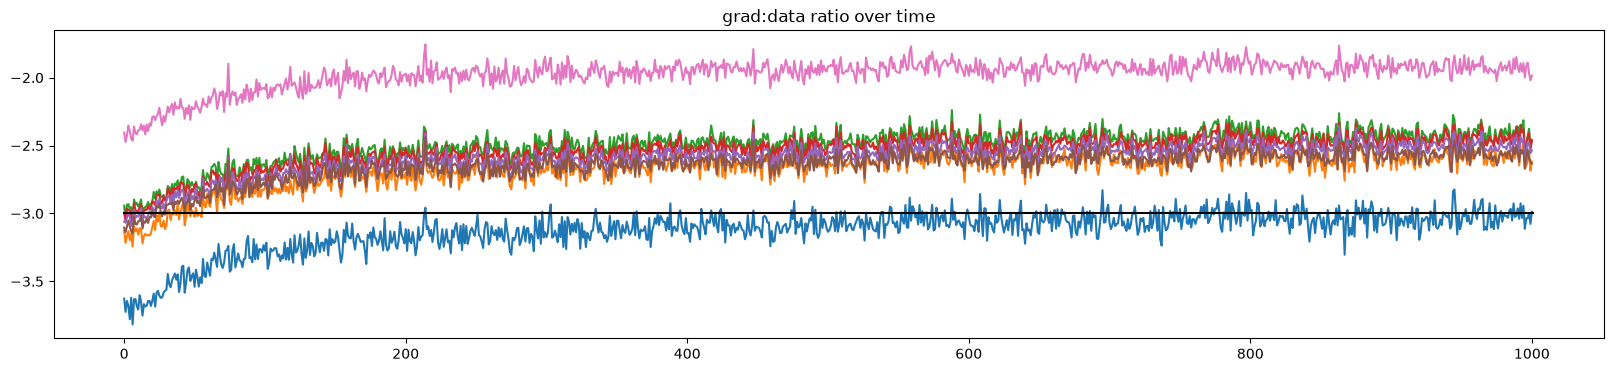

In [26]:
plt.figure(figsize = (20, 4))
legends = []
for i, p in enumerate(parameters):
    if p.ndim == 2:
        plt.plot([up[j][i] for j in range(len(up))])
        legends.append('param %d' % i)
plt.plot([0, len(up)], [-3, -3], 'k') # horizontal line indicating a good ratio
plt.title('grad:data ratio over time')

To be honest, due to the presence of those normalization layers, we can directly abandon the gain and the divsion by sqrt(fan_in) since the scaling will be taken care of by the batch norm layer. However, it is worth noting that although the effect on the first three graph is not very significant, it impacts the fourth graph somehow, that is because the value from back prpogation will change, and therefore, we may want to calibrate the learning rate for the curves in the fourth to meet 1e-3. (you can try remove the addition scaling and check the fourth graph)